Nolan Allen

Professor Dmitry Kurochkin

CSCI S-89 Deep Learning, Summer 2024

7 August 2024

Final Project: Gesture Recognition in Underwater Robotics

# Abstract

Gesture recognition in robotics aims to enable intuitive and seamless communication between humans and robots. This project attempts to develop a deep learning model specifically designed to recognize gestures in underwater environments, addressing the need for effective human-robot interaction where traditional physical interfaces are impractical.

The technology is particularly suited for scenarios where humans and robots coexist, such as autonomous drones, underwater vehicles, and assistive robotics in healthcare settings. My interest in this project stems from a background in robotics and a fascination with integrating deep learning into human-robot interaction, presenting a challenging yet rewarding opportunity to enhance communication efficiency.

By focusing on underwater robotics, this project explores a less-studied application of gesture recognition, leveraging deep learning techniques to improve interaction in environments where visual and environmental factors are unique. This work aims to explore the field of gesture recognition and lay a foundation for future developments in intuitive robotic communication.

YouTube video presentation: https://youtu.be/yE0yjXo3DMc

# Hardware and Software Versions
- TensorFlow version 2.17.0
- Keras version 3.4.1
- Jypyter Notebook version 7.0.8
- M2 Macbook Pro
- 16 GB Memory
- macOS 14.5

# The Dataset

## Overview

For this project, I utilized the CADDY Underwater Gesture Dataset, which provides a valuable resource for gesture recognition in underwater environments. The dataset includes thousands of frames from 640x480 stereo video feeds, which can be assembled into video clips of varying lengths. **The dataset included in this project is a very small sample (60 stereo frames), and it is not large enough to produce accurate results; it is strictly for the purpose of verifying that the code works.** The full dataset can be downloaded here via the "Complete dataset – 2.5GB" option: http://www.caddian.eu//CADDY-Underwater-Gestures-Dataset.html

##### Key characteristics of the dataset:
- Gestures: 16 distinct gestures
- Video Clips: 903 stereo-vision RGB video clips
- Recording Scenarios: 8 different underwater scenarios

Although the dataset is relatively modest in size, it is suitable given the limitations of my computer's RAM, which constrains the use of larger datasets. Despite its size, I expect the dataset to support the development of a model with reasonably good accuracy for gesture recognition in this context.

## Load and Preprocess the Data

First, let's open the dataset take a look around.

In [2]:
import os

# Define paths and file names
zip_name = 'CADDY_gestures_complete_v2_release'
extract_dir = 'data/'
dataset_dir = os.path.join(extract_dir, zip_name + '/')

In [ ]:
import zipfile

# Unzip the dataset
with zipfile.ZipFile(zip_name + '.zip', 'r') as zip_ref:
    zip_ref.extractall(extract_dir)

In [4]:
import pandas as pd

# Load the CSV file
csv_path = os.path.join(dataset_dir, 'CADDY_gestures_all_true_positives_release_v2.csv')
df = pd.read_csv(csv_path)

# Filter rows where synthetic is 0 (images from other rows are not present in the zip file)
df_filtered = df[df['synthetic'] == 0]

You can now see the extracted zip file in your file system. Feel free to take a look and see how it is organized. To get a better sense of the dataset, let's look at some statistics regarding clip lengths.

In [5]:
import statistics

lengths = []

current_label = None
video_frames = 0

for _, row in df_filtered.iterrows():
    label_name = row['label name']

    if label_name != current_label:
        # New video clip starts
        if current_label is not None:
            # Save the length of the previous video clip
            lengths.append(video_frames)

        # Reset for the new video clip
        current_label = label_name
        video_frames = 0

    video_frames += 1

# Add the length of the last video clip (omitted in above loop)
if current_label is not None:
    lengths.append(video_frames)

print(f'Videos: {len(lengths)}')
print(f'Range: [{min(lengths)}, {max(lengths)}]')
print(f'Median: {statistics.median(lengths)}')
print(f'Average: {sum(lengths)/len(lengths)}')

Videos: 903
Range: [1, 133]
Median: 7
Average: 10.231450719822814


With a median clip length of seven frames, we can set the required video length to 8, truncating and padding as necessary. This will allow the majority of video clips to have one frame of padding or less. We can also set a minimum video length of 4. This ensures that we have at least four frames of actual data in each video clip.

As a note, I had originally chosen 12 and 0 as the required video and minimum video lengths, respectively. Through training, I discovered that 4-8 frames was the optimal duration for recognizing a gesture in this dataset, enhancing training efficiency without compromising on model accuracy. The framerate of the dataset is rather low, so 4-8 frames covers a decent amount of time while still capturing the gesture.

Next, we must assemble the video clips. In the code below, we get the filepaths for the various frames from the CSV file, then load them, concatenate left and right into stereo images, and process them into video clips stored as numpy arrays. You'll notice that we also rescale the images from their original 640x480 down to 160x120; this is done both for model efficiency and so that dataset will use less RAM.

In [6]:
import cv2
import numpy as np

# Define the fixed length for video clips (chosen based on performance and dataset statistics)
VIDEO_LENGTH = 8
MIN_VIDEO_LENGTH = 4

# Load two images from two filepaths and combine into a stereo pair
def load_image_pair(left_path, right_path, dim=(160,120)):
    left_img = cv2.imread(left_path)
    right_img = cv2.imread(right_path)
    # Resize images
    left_img = cv2.resize(left_img, dim, interpolation=cv2.INTER_AREA)
    right_img = cv2.resize(right_img, dim, interpolation=cv2.INTER_AREA)
    return np.concatenate([left_img, right_img], axis=-1)

# Assemble the data listed in a dataframe into videos and corresponding labels
def process_videos(df_filtered):
    videos = []
    labels = []

    current_label = None
    video_frames = []

    for _, row in df_filtered.iterrows():
        label_name = row['label name']

        if label_name != current_label:
            # New video clip starts
            if current_label is not None:
                # Pad video clip if needed
                video_clip = np.array(video_frames)
                if video_clip.shape[0] >= MIN_VIDEO_LENGTH:
                    if video_clip.shape[0] < VIDEO_LENGTH:
                        padding = [(0, VIDEO_LENGTH - video_clip.shape[0])] + [(0, 0)] * (video_clip.ndim - 1)
                        video_clip = np.pad(video_clip, padding, mode='constant')
                    # Save the previous video clip
                    videos.append(video_clip)
                    labels.append(current_label)

            # Reset for the new video clip
            current_label = label_name
            video_frames = []

        if len(video_frames) < VIDEO_LENGTH:
            left_path = os.path.join(dataset_dir, row['stereo left'][1:])
            right_path = os.path.join(dataset_dir, row['stereo right'][1:])
            frame = load_image_pair(left_path, right_path)
            video_frames.append(frame)

    # Add the last video clip (omitted in above loop)
    if current_label is not None:
        # Pad video clip if needed
        video_clip = np.array(video_frames)
        if video_clip.shape[0] >= MIN_VIDEO_LENGTH:
            if video_clip.shape[0] < VIDEO_LENGTH:
                padding = [(0, VIDEO_LENGTH - video_clip.shape[0])] + [(0, 0)] * (video_clip.ndim - 1)
                video_clip = np.pad(video_clip, padding, mode='constant')
            videos.append(video_clip)
            labels.append(current_label)

    return np.array(videos), np.array(labels)

# Assemble image and csv data into labeled video data
videos, labels = process_videos(df_filtered)

# Normalize images (pixel values are [0, 255])
videos = videos / 255.0

Now we need to encode the dataset's labels into a format that can be used as output by the neural network. Let's use sparse encodings to save space.

In [7]:
from sklearn.preprocessing import LabelEncoder

# Convert the string labels to numerical labels
label_encoder = LabelEncoder()
encoded_labels = label_encoder.fit_transform(labels)

In [8]:
from sklearn.model_selection import train_test_split

# Split the dataset into training and validation sets
X_train, X_val, y_train, y_val = train_test_split(videos, encoded_labels, test_size=0.2, random_state=42)

In [9]:
# Free memory by deleting large variables
del videos
del encoded_labels

import gc
gc.collect()

0

The full dataset has 16 classes. This suggests that random guessing would achieve 1/16 or 6.25% accuracy. This is good to know for when we train our models.

In [10]:
f'Output Classes: {len(label_encoder.classes_)}'

'Output Classes: 16'

## Set up Data Augmentation

Originally, I felt that data augmentation was important for this dataset; having only eight recording scenarios, each with a distinct water transparency, color, and lighting seemed like a limitation that could be overcome via augmentation. However, I determined through repeated testing that any amount of augmentation reduced validation accuracy as well as training accuracy. As I had determined validation accuracy to be my main metric, I decided to not augment my data. This will be discussed further later.

The code here can be converted to a code cell and run if you wish to train with the augmented data. Note that any training code `model.fit(X_train, y_train, ` must be changed to `model.fit(train_dataset, ` to use the augmented dataset. You can also change the augmentation parameters to see how that affects training.

```python
import tensorflow as tf

# Apply agumentation to a single frame of a video clip
def augment_frame(frame):
    # Random horizontal flip
    frame = tf.image.random_flip_left_right(frame)

    # Random rotation
    #frame = tf.image.rot90(frame, k=tf.random.uniform([], maxval=4, dtype=tf.int32))

    # Random brightness and contrast
    frame = tf.image.random_brightness(frame, max_delta=0.1)
    frame = tf.image.random_contrast(frame, lower=0.9, upper=1.1)

    return frame

# Apply agumentation to an entire video clip
def augment_video_clip(video_clip):
    video_clip = tf.map_fn(augment_frame, video_clip, dtype=tf.float32)
    return video_clip

# Convert numpy arrays to TensorFlow datasets
def create_tf_dataset(videos, labels, batch_size):
    dataset = tf.data.Dataset.from_tensor_slices((videos, labels))
    dataset = dataset.map(lambda x, y: (tf.cast(x, tf.float32), tf.cast(y, tf.int32)))
    dataset = dataset.map(lambda x, y: (augment_video_clip(x), y))
    dataset = dataset.batch(batch_size).shuffle(buffer_size=1000).prefetch(buffer_size=tf.data.AUTOTUNE)
    return dataset

# Create datasets for training and validation
batch_size = 16
train_dataset = create_tf_dataset(X_train, y_train, batch_size)
```

The following code discards the unagumented training data to save memory if needed. Only convert the following to a code cell if you have limited memory and do not wish to train with the unaugmented data.

```python
# Free memory by deleting large variables
del X_train
del y_train

import gc
gc.collect()
```

# Defining and Training Models

## First Approach - A Good Start

The idea behind this first approach is to use 3D convolutional layers to catch dependencies between frames and an LSTM to capture longer-term dependencies. Dropout and batch normalization layers were added later to improve results.

Some notes on compile parameters:
- The loss function `sparse_categorical_crossentropy` was chosen because we are using sparse encodings, as mentioned in the Load and Preprocess the Data section.
- Accuracy is selected as a metric to track because that ultimately determines how successful our categorization model is. At a certain point, we don't care how certain the model is of its classification, which is what we'd see if we only looked at loss. Validation accuracy gives us a quantifiable judgement of how well the model is expected to generalize to unseen data.

In [149]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv3D, MaxPooling3D, Dropout, TimeDistributed, Dense, Flatten, LSTM, BatchNormalization
from tensorflow.keras.optimizers import Adam

def create_gesture_recognition_model(video_length, num_classes):
    model = Sequential()
    
    # 3D Convolutional Layers
    model.add(Conv3D(filters=32, kernel_size=(3, 3, 3), activation='relu', input_shape=(video_length, 120, 160, 6)))
    model.add(BatchNormalization())
    model.add(MaxPooling3D(pool_size=(1, 2, 2)))
    model.add(Dropout(0.5))
    
    model.add(Conv3D(filters=64, kernel_size=(3, 3, 3), activation='relu'))
    model.add(BatchNormalization())
    model.add(MaxPooling3D(pool_size=(1, 2, 2)))
    model.add(Dropout(0.5))
    
    model.add(Conv3D(filters=128, kernel_size=(3, 3, 3), activation='relu'))
    model.add(BatchNormalization())
    model.add(MaxPooling3D(pool_size=(1, 2, 2)))
    model.add(Dropout(0.5))
    
    # TimeDistributed layer to apply Dense layer to each time step
    model.add(TimeDistributed(Flatten()))
    model.add(LSTM(64, return_sequences=False, dropout=0.5))  # LSTM layer
    model.add(Dense(64, activation='relu'))
    model.add(Dropout(0.5))
    
    # Output Layer
    model.add(Dense(num_classes, activation='softmax'))
    
    # Compile the model
    model.compile(optimizer=Adam(), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    
    return model

model = create_gesture_recognition_model(video_length=VIDEO_LENGTH,
                                         num_classes=len(label_encoder.classes_))
model.summary()

/opt/anaconda3/lib/python3.12/site-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv3d (Conv3D)                 │ (None, 6, 118, 158,    │         5,216 │
│                                 │ 32)                    │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 6, 118, 158,    │           128 │
│ (BatchNormalization)            │ 32)                    │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling3d (MaxPooling3D)    │ (None, 6, 59, 79, 32)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 6, 59, 79, 32)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3d_1 (Conv3D)               │ (None, 4, 57, 77, 64)  │        55,360 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 4, 57, 77, 64)  │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling3d_1 (MaxPooling3D)  │ (None, 4, 28, 38, 64)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 4, 28, 38, 64)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3d_2 (Conv3D)               │ (None, 2, 26, 36, 128) │       221,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 2, 26, 36, 128) │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling3d_2 (MaxPooling3D)  │ (None, 2, 13, 18, 128) │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 2, 13, 18, 128) │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_7              │ (None, 2, 29952)       │             0 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 64)             │     7,684,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 16)             │         1,040 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,972,336 (30.41 MB)

 Trainable params: 7,971,888 (30.41 MB)

 Non-trainable params: 448 (1.75 KB)

Now let's train it!

In [151]:
# Train the model
history_1 = model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=20, batch_size=16)

Epoch 1/20
37/37 ━━━━━━━━━━━━━━━━━━━━ 125s 3s/step - accuracy: 0.1838 - loss: 2.6856 - val_accuracy: 0.2552 - val_loss: 2.5484
Epoch 2/20
37/37 ━━━━━━━━━━━━━━━━━━━━ 123s 3s/step - accuracy: 0.2042 - loss: 2.5526 - val_accuracy: 0.2345 - val_loss: 2.5557
Epoch 3/20
37/37 ━━━━━━━━━━━━━━━━━━━━ 120s 3s/step - accuracy: 0.2532 - loss: 2.4877 - val_accuracy: 0.2138 - val_loss: 2.5330
Epoch 4/20
37/37 ━━━━━━━━━━━━━━━━━━━━ 120s 3s/step - accuracy: 0.2406 - loss: 2.4464 - val_accuracy: 0.2621 - val_loss: 2.4520
Epoch 5/20
37/37 ━━━━━━━━━━━━━━━━━━━━ 119s 3s/step - accuracy: 0.2076 - loss: 2.3990 - val_accuracy: 0.2759 - val_loss: 2.4402
Epoch 6/20
37/37 ━━━━━━━━━━━━━━━━━━━━ 119s 3s/step - accuracy: 0.2205 - loss: 2.4954 - val_accuracy: 0.2828 - val_loss: 2.4017
Epoch 7/20
37/37 ━━━━━━━━━━━━━━━━━━━━ 119s 3s/step - accuracy: 0.2554 - loss: 2.4043 - val_accuracy: 0.2759 - val_loss: 2.3201
Epoch 8/20
37/37 ━━━━━━━━━━━━━━━━━━━━ 118s 3s/step - accuracy: 0.2241 - loss: 2.4609 - val_accuracy: 0.2621 - v

In [165]:
# Train the model more
history_2 = model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=20, batch_size=16)

Epoch 1/20
37/37 ━━━━━━━━━━━━━━━━━━━━ 118s 3s/step - accuracy: 0.2404 - loss: 2.3135 - val_accuracy: 0.2621 - val_loss: 2.3181
Epoch 2/20
37/37 ━━━━━━━━━━━━━━━━━━━━ 117s 3s/step - accuracy: 0.2728 - loss: 2.2510 - val_accuracy: 0.2759 - val_loss: 2.2783
Epoch 3/20
37/37 ━━━━━━━━━━━━━━━━━━━━ 117s 3s/step - accuracy: 0.2689 - loss: 2.3314 - val_accuracy: 0.2759 - val_loss: 2.3115
Epoch 4/20
37/37 ━━━━━━━━━━━━━━━━━━━━ 115s 3s/step - accuracy: 0.2547 - loss: 2.3054 - val_accuracy: 0.2759 - val_loss: 2.2858
Epoch 5/20
37/37 ━━━━━━━━━━━━━━━━━━━━ 117s 3s/step - accuracy: 0.2766 - loss: 2.3031 - val_accuracy: 0.2621 - val_loss: 2.3350
Epoch 6/20
37/37 ━━━━━━━━━━━━━━━━━━━━ 116s 3s/step - accuracy: 0.2553 - loss: 2.2952 - val_accuracy: 0.2552 - val_loss: 2.3217
Epoch 7/20
37/37 ━━━━━━━━━━━━━━━━━━━━ 117s 3s/step - accuracy: 0.2656 - loss: 2.3038 - val_accuracy: 0.2483 - val_loss: 2.3157
Epoch 8/20
37/37 ━━━━━━━━━━━━━━━━━━━━ 115s 3s/step - accuracy: 0.2854 - loss: 2.2557 - val_accuracy: 0.2276 - v

In [189]:
# Train the model even more
history_3 = model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=20, batch_size=16)

Epoch 1/20
37/37 ━━━━━━━━━━━━━━━━━━━━ 116s 3s/step - accuracy: 0.2653 - loss: 2.2746 - val_accuracy: 0.2483 - val_loss: 2.2754
Epoch 2/20
37/37 ━━━━━━━━━━━━━━━━━━━━ 116s 3s/step - accuracy: 0.2686 - loss: 2.2839 - val_accuracy: 0.2621 - val_loss: 2.2458
Epoch 3/20
37/37 ━━━━━━━━━━━━━━━━━━━━ 116s 3s/step - accuracy: 0.3030 - loss: 2.2675 - val_accuracy: 0.2621 - val_loss: 2.2772
Epoch 4/20
37/37 ━━━━━━━━━━━━━━━━━━━━ 117s 3s/step - accuracy: 0.3093 - loss: 2.2549 - val_accuracy: 0.2483 - val_loss: 2.2759
Epoch 5/20
37/37 ━━━━━━━━━━━━━━━━━━━━ 115s 3s/step - accuracy: 0.2664 - loss: 2.2963 - val_accuracy: 0.2690 - val_loss: 2.2558
Epoch 6/20
37/37 ━━━━━━━━━━━━━━━━━━━━ 116s 3s/step - accuracy: 0.2893 - loss: 2.2334 - val_accuracy: 0.2207 - val_loss: 2.3026
Epoch 7/20
37/37 ━━━━━━━━━━━━━━━━━━━━ 116s 3s/step - accuracy: 0.2805 - loss: 2.1449 - val_accuracy: 0.2276 - val_loss: 2.3092
Epoch 8/20
37/37 ━━━━━━━━━━━━━━━━━━━━ 116s 3s/step - accuracy: 0.3038 - loss: 2.1622 - val_accuracy: 0.2552 - v

When I initially trained it, the model achieved 15-20% accuracy. Tuning hyperparameters achieved maximum accuracies around 30% for train and validation, which is approximately what you should see now. Now let's graph the train and validation data to see how the model changed over time.

In [ ]:
import numpy as np

def concatenate_histories(*histories):
    combined_history = {}

    # Iterate through each history object
    for history in histories:
        history_dict = history.history
        for key in history_dict.keys():
            if key in combined_history:
                # Append the new data to the existing data
                combined_history[key] = np.concatenate((combined_history[key], history_dict[key]))
            else:
                # Initialize the combined data with the current history data
                combined_history[key] = history_dict[key]

    return combined_history

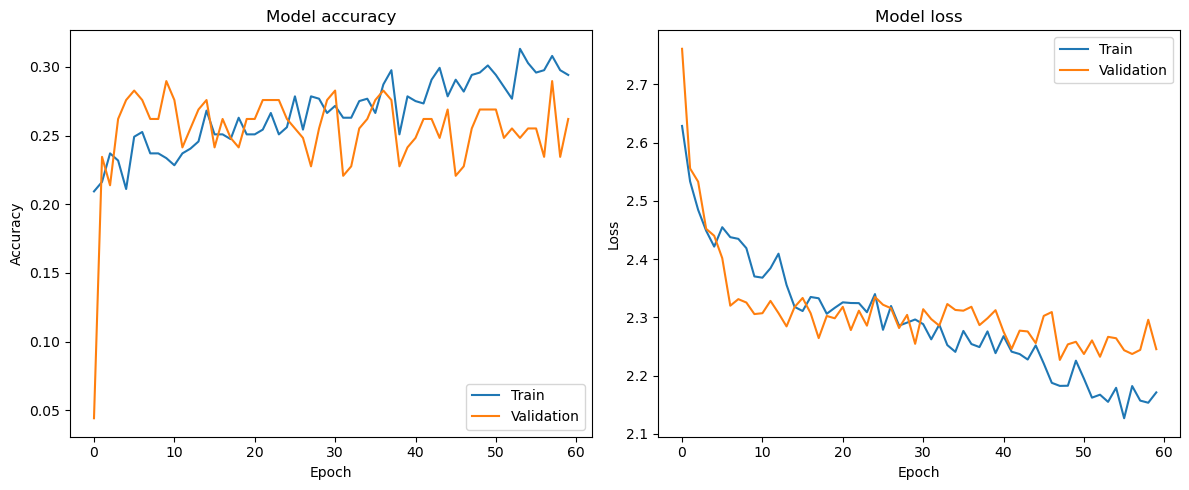

In [218]:
import matplotlib.pyplot as plt

# Extract the history data
history_dict = concatenate_histories(history_1, history_2, history_3)

# Plot training & validation accuracy values
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history_dict['accuracy'])
plt.plot(history_dict['val_accuracy'])
plt.title('Model accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(['Train', 'Validation'])

# Plot training & validation loss values
plt.subplot(1, 2, 2)
plt.plot(history_dict['loss'])
plt.plot(history_dict['val_loss'])
plt.title('Model loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(['Train', 'Validation'])

plt.tight_layout()
plt.show()

This is better performance than random guessing, which as we said before should produce an accuracy of 6.25%, but it is still far from ideal. Due to the train and validation accuracy, I think it is safe to conclude that the model itself is not sufficiently complex to capture the nuances in the dataset.

## Second Approach - Could Simpler Be Better?

This model uses reformatted input data - instead of processing and categorizing entire video clips, this model takes one frame (non-stereo) at a time as input. It is, in fact, the same model architecture that was provided in Assignment 3 of this course to categorize images of dogs and cats.

```python
# Basic 2D CNN 
model = models.Sequential()
model.add(layers.Conv2D(32, (3, 3), activation='relu',
                        input_shape=(120, 160, 3)))
model.add(layers.MaxPooling2D((2, 2)))
model.add(layers.Conv2D(64, (3, 3), activation='relu'))
model.add(layers.MaxPooling2D((2, 2)))
model.add(layers.Conv2D(128, (3, 3), activation='relu'))
model.add(layers.MaxPooling2D((2, 2)))
model.add(layers.Conv2D(128, (3, 3), activation='relu'))
model.add(layers.MaxPooling2D((2, 2)))
model.add(layers.Flatten())
model.add(layers.Dense(512, activation='relu'))
model.add(layers.Dense(len(label_encoder.classes_),
                       activation='softmax'))

# Compile the model
model.compile(optimizer=Adam(), loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# Train the model
history = model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=40, batch_size=16)
```

As a note, this code is left unexecuted here as it requires additional train and validation sets with the reformatted input, and I am currently unable to handle the required RAM to hold all of these sets. After brief training, the model performed surprisingly well considering it ignores temporal dependencies. This suggests that features in the image could be potentially more important than temporal dependencies. Let's incorporate this idea into our next model.

## Third Approach - Let’s Combine What We’ve Learned

This model starts with a 2D CNN (time distributed) for feature extraction, intended to capture hand and finger position and orientation. That then feeds into an LSTM layer intended to identify temporal dependencies. Note that this code represents the final and best version of the model. The initial version had different hyperparameters.

In [15]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import InputLayer, TimeDistributed, Conv2D, MaxPooling2D, Flatten, LSTM, Dense, Dropout
from tensorflow.keras.optimizers import Adam

def create_gesture_recognition_model(input_shape, num_classes):
    model = Sequential()

    # Input layer
    model.add(InputLayer(shape=input_shape))

    # 2D CNN for feature extraction
    model.add(TimeDistributed(Conv2D(filters=16, kernel_size=(3, 3), activation='relu', padding='same')))
    model.add(TimeDistributed(MaxPooling2D(pool_size=(2, 2))))
    model.add(TimeDistributed(Conv2D(filters=32, kernel_size=(3, 3), activation='relu', padding='same')))
    model.add(TimeDistributed(MaxPooling2D(pool_size=(2, 2))))
    model.add(TimeDistributed(Conv2D(filters=64, kernel_size=(3, 3), activation='relu', padding='same')))
    model.add(TimeDistributed(MaxPooling2D(pool_size=(2, 2))))
    model.add(TimeDistributed(Flatten()))

    # LSTM for temporal dependencies
    model.add(LSTM(128, return_sequences=False, dropout=0.5, recurrent_dropout=0.5))
    model.add(Dense(128, activation='relu'))
    model.add(Dropout(0.5))

    # Output layer
    model.add(Dense(num_classes, activation='softmax'))

    # Compile the model
    model.compile(optimizer=Adam(learning_rate=1e-4), loss='sparse_categorical_crossentropy', metrics=['accuracy'])

    return model

model = create_gesture_recognition_model(input_shape=(VIDEO_LENGTH, 120, 160, 6),
                                         num_classes=len(label_encoder.classes_))
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ time_distributed                │ (None, 8, 120, 160,    │           880 │
│ (TimeDistributed)               │ 16)                    │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_1              │ (None, 8, 60, 80, 16)  │             0 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_2              │ (None, 8, 60, 80, 32)  │         4,640 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_3              │ (None, 8, 30, 40, 32)  │             0 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_4              │ (None, 8, 30, 40, 64)  │        18,496 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_5              │ (None, 8, 15, 20, 64)  │             0 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_6              │ (None, 8, 19200)       │             0 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 128)            │     9,896,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │         2,064 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,939,040 (37.91 MB)

 Trainable params: 9,939,040 (37.91 MB)

 Non-trainable params: 0 (0.00 B)

The initial training yielded 35% validation accuracy - already better than both of our previous models!

##### Hyperparameters tuned in subsequent training sessions:
- Adam’s default learning rate of 1e-3 lead to stagnant validation accuracy; 1e-5 improved results, but 1e-4 produced by far the best validation accuracy of 40%
- With training accuracy approaching 100%, added and tuned dropouts, which increased validation accuracy and slowed overtraining
- Overtraining was still a problem
- Tried reducing the complexity of the model (filter count, convolutional layers, LSTM inputs); however, validation accuracy increased with a more complex model
- Implemented L2 regularization (i.e. penalizing larger weights) in various amounts; this reduced both training and validation accuracy
- Data augmentation attempted (code shown in Set up Data Augmentation section); this also decreased both training accuracy and validation accuracy
- Applied learning rate scheduling, specifically with ReduceLROnPlateau, which appeared to have no significant effect on max accuracy for training or validation
- Overall, only dropout layers increased validation accuracy while reducing overtraining

Code including L2 regularization, learning rate scheduling, early stopping, data augmentation, and a reduced complexity are shown below. This code is set to not run because it is representative of the things that did not work. Also note that `model.fit(train_dataset, ` uses data augmentation and will only run if that has been enabled previously. If that has not been enabled, you will have to replace it with `model.fit(X_train, y_train, ` to use unaugmented data.

```python
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

def create_gesture_recognition_model(input_shape, num_classes):
    model = Sequential()

    model.add(InputLayer(shape=input_shape))

    model.add(TimeDistributed(Conv2D(filters=16, kernel_size=(3, 3), activation='relu', padding='same', kernel_regularizer=l2(0.01))))
    model.add(TimeDistributed(MaxPooling2D(pool_size=(2, 2))))
    model.add(TimeDistributed(Conv2D(filters=32, kernel_size=(3, 3), activation='relu', padding='same', kernel_regularizer=l2(0.01))))
    model.add(TimeDistributed(MaxPooling2D(pool_size=(2, 2))))
    model.add(TimeDistributed(Flatten()))

    model.add(LSTM(64, return_sequences=False, dropout=0.5, recurrent_dropout=0.5))
    model.add(Dense(64, activation='relu', kernel_regularizer=l2(0.01)))
    model.add(Dropout(0.5))

    model.add(Dense(num_classes, activation='softmax'))

    model.compile(optimizer=Adam(learning_rate=1e-4), loss='sparse_categorical_crossentropy', metrics=['accuracy'])

    return model

# Initialize and print model summary
model = create_gesture_recognition_model(input_shape=(VIDEO_LENGTH, 120, 160, 6),
                                         num_classes=len(label_encoder.classes_))
model.summary()

# Callbacks
early_stopping = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
model_checkpoint = ModelCheckpoint('best_model.keras', monitor='val_loss', save_best_only=True)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.1, patience=3)

# Train model with callbacks
history = model.fit(train_dataset, validation_data=(X_val, y_val),
                    epochs=50, batch_size=32,
                    callbacks=[early_stopping, model_checkpoint, reduce_lr])

```

Finally, here is the training data from the most successful hyperparameters for this model.

In [17]:
# Train the model
history = model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=40, batch_size=16)
#history = model.fit(train_dataset, validation_data=(X_val, y_val), epochs=40, batch_size=16) # this line uses data augmentation, if implented above
model.save('cnn_lstm_40.keras')

Epoch 1/40
37/37 ━━━━━━━━━━━━━━━━━━━━ 31s 807ms/step - accuracy: 0.1833 - loss: 2.6565 - val_accuracy: 0.2759 - val_loss: 2.4235
Epoch 2/40
37/37 ━━━━━━━━━━━━━━━━━━━━ 29s 778ms/step - accuracy: 0.2256 - loss: 2.4837 - val_accuracy: 0.2759 - val_loss: 2.3837
Epoch 3/40
37/37 ━━━━━━━━━━━━━━━━━━━━ 29s 771ms/step - accuracy: 0.2014 - loss: 2.4924 - val_accuracy: 0.2759 - val_loss: 2.3517
Epoch 4/40
37/37 ━━━━━━━━━━━━━━━━━━━━ 29s 790ms/step - accuracy: 0.2506 - loss: 2.4451 - val_accuracy: 0.2759 - val_loss: 2.3636
Epoch 5/40
37/37 ━━━━━━━━━━━━━━━━━━━━ 29s 784ms/step - accuracy: 0.2473 - loss: 2.4301 - val_accuracy: 0.2759 - val_loss: 2.3396
Epoch 6/40
37/37 ━━━━━━━━━━━━━━━━━━━━ 29s 777ms/step - accuracy: 0.2538 - loss: 2.3410 - val_accuracy: 0.2828 - val_loss: 2.3079
Epoch 7/40
37/37 ━━━━━━━━━━━━━━━━━━━━ 29s 771ms/step - accuracy: 0.2631 - loss: 2.3533 - val_accuracy: 0.2759 - val_loss: 2.2876
Epoch 8/40
37/37 ━━━━━━━━━━━━━━━━━━━━ 29s 769ms/step - accuracy: 0.2775 - loss: 2.2895 - val_accu

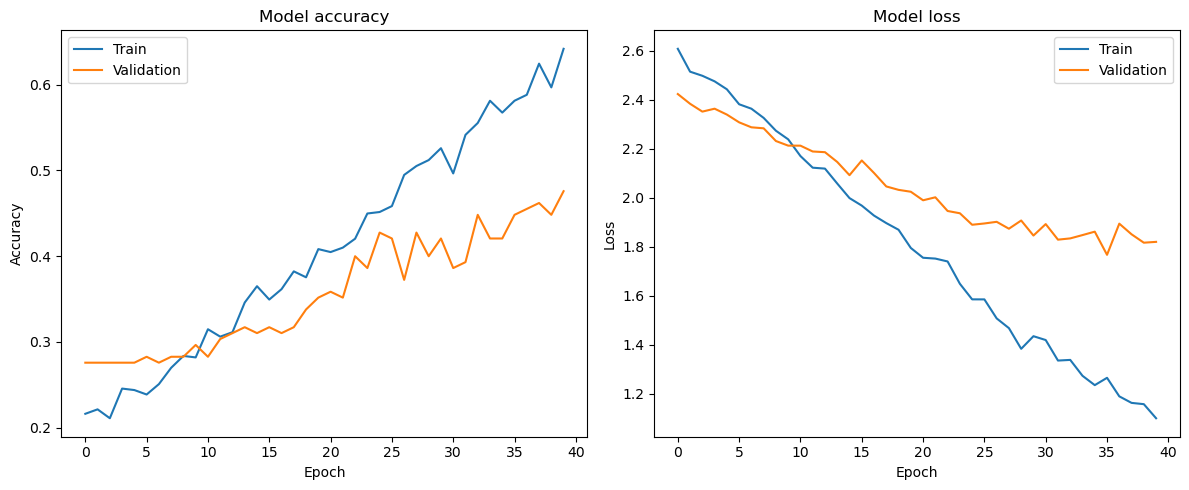

In [18]:
import matplotlib.pyplot as plt

# Extract the history data
history_dict = history.history

# Plot training & validation accuracy values
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history_dict['accuracy'])
plt.plot(history_dict['val_accuracy'])
plt.title('Model accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(['Train', 'Validation'])

# Plot training & validation loss values
plt.subplot(1, 2, 2)
plt.plot(history_dict['loss'])
plt.plot(history_dict['val_loss'])
plt.title('Model loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(['Train', 'Validation'])

plt.tight_layout()
plt.show()

After 40 epochs, the model achieved 47% validation accuracy! And according to the graph, it's still improving. Let's train for a few more epochs, recording the best model as we go.

In [38]:
from tensorflow.keras.models import load_model
from tensorflow.keras.callbacks import ModelCheckpoint

# Load the model
model = load_model('cnn_lstm_40.keras')

# Define the ModelCheckpoint callback
model_checkpoint = ModelCheckpoint(
    filepath='best_model.keras',
    monitor='val_accuracy',
    save_best_only=True,
    mode='max',
    verbose=1
)

# Continue training
history2 = model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=20, batch_size=16, callbacks=[model_checkpoint])

Epoch 1/20
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 755ms/step - accuracy: 0.6452 - loss: 1.0685
Epoch 1: val_accuracy improved from -inf to 0.40690, saving model to best_model.keras
37/37 ━━━━━━━━━━━━━━━━━━━━ 32s 812ms/step - accuracy: 0.6449 - loss: 1.0691 - val_accuracy: 0.4069 - val_loss: 1.7661
Epoch 2/20
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 741ms/step - accuracy: 0.6591 - loss: 0.9913
Epoch 2: val_accuracy improved from 0.40690 to 0.46897, saving model to best_model.keras
37/37 ━━━━━━━━━━━━━━━━━━━━ 29s 784ms/step - accuracy: 0.6588 - loss: 0.9921 - val_accuracy: 0.4690 - val_loss: 1.8174
Epoch 3/20
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 744ms/step - accuracy: 0.6278 - loss: 1.0383
Epoch 3: val_accuracy did not improve from 0.46897
37/37 ━━━━━━━━━━━━━━━━━━━━ 29s 783ms/step - accuracy: 0.6286 - loss: 1.0378 - val_accuracy: 0.4483 - val_loss: 1.8463
Epoch 4/20
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 749ms/step - accuracy: 0.6873 - loss: 0.9425
Epoch 4: val_accuracy did not improve from 0.46897
37/37 ━━━━━━━━━━━━━━━━━━━

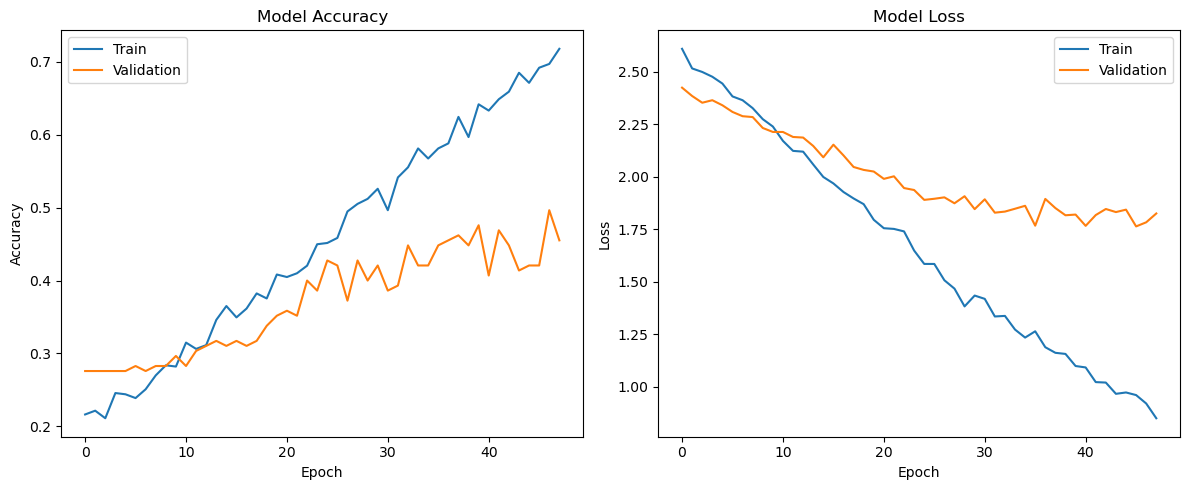

In [89]:
import matplotlib.pyplot as plt

combined_history = concatenate_histories(history, history2)

# Plot training & validation accuracy values
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(combined_history['accuracy'])
plt.plot(combined_history['val_accuracy'])
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(['Train', 'Validation'])

# Plot training & validation loss values
plt.subplot(1, 2, 2)
plt.plot(combined_history['loss'])
plt.plot(combined_history['val_loss'])
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(['Train', 'Validation'])

plt.tight_layout()
plt.show()

On epoch 47, we achieved 49.655% validation accuracy! Let's round to 50% to make things simpler. This is definitely the best performance of the model so far. Given the extent of the experimenting I have done, I believe 50% accuracy is the best I can achieve without a fundamentally different approach (details given in the Future Work section).

# Data Analysis

Let's load our best model and explore more deeply how it performs.

In [44]:
from tensorflow.keras.models import load_model

# Load the model
model = load_model('best_model.keras')

So far, we've evaluated the model based on validation accuracy across all classes. What if we break down accuracy for each class? While we're at it, let's put it alongside the number of instances of each class in the validation data.

5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 201ms/step


/var/folders/m0/jyv2gtk95yqfvwmjs3m3rp2r0000gn/T/ipykernel_84155/1831999079.py:24: RuntimeWarning: invalid value encountered in divide
  class_accuracies = np.diag(conf_matrix) / np.sum(conf_matrix, axis=1)


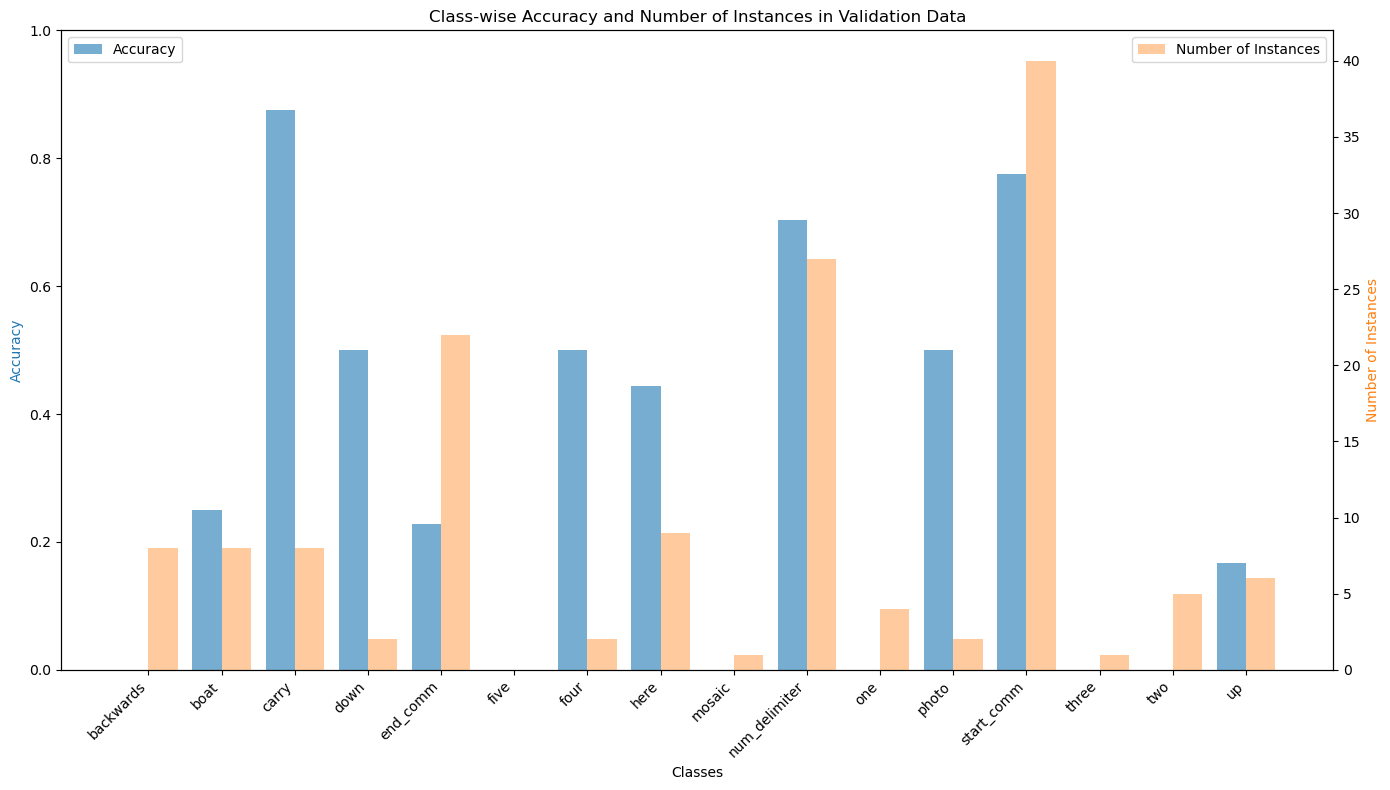

In [74]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
from collections import Counter

# Predict on validation data
y_pred_probs = model.predict(X_val)
y_pred = np.argmax(y_pred_probs, axis=1)

# Calculate confusion matrix
conf_matrix = confusion_matrix(y_val, y_pred, labels=np.arange(len(label_encoder.classes_)))

# Number of classes
num_classes = len(label_encoder.classes_)

# Pad the confusion matrix if necessary
if conf_matrix.shape != (num_classes, num_classes):
    padded_conf_matrix = np.zeros((num_classes, num_classes), dtype=int)
    min_dim = min(conf_matrix.shape[0], num_classes)
    padded_conf_matrix[:min_dim, :min_dim] = conf_matrix
    conf_matrix = padded_conf_matrix

# Calculate accuracy per class
class_accuracies = np.diag(conf_matrix) / np.sum(conf_matrix, axis=1)

# Count the instances per class in the validation data
class_counts = Counter(y_val)
instance_counts = [class_counts.get(i, 0) for i in range(num_classes)]

# Retrieve class names from the label encoder
class_names = label_encoder.classes_

# Set up the figure and axis
fig, ax1 = plt.subplots(figsize=(14, 8))

# Set bar width
bar_width = 0.4
index = np.arange(num_classes)

# Plot class-wise accuracy
bar1 = ax1.bar(index - bar_width/2, class_accuracies, bar_width, label='Accuracy', color='tab:blue', alpha=0.6)

# Create a second y-axis for the number of instances
ax2 = ax1.twinx()

# Plot number of instances
bar2 = ax2.bar(index + bar_width/2, instance_counts, bar_width, label='Number of Instances', color='tab:orange', alpha=0.4)

# Labeling
ax1.set_xlabel('Classes')
ax1.set_ylabel('Accuracy', color='tab:blue')
ax2.set_ylabel('Number of Instances', color='tab:orange')
ax1.set_xticks(index)
ax1.set_xticklabels(class_names, rotation=45, ha='right')
ax1.set_ylim(0, 1)

# Add title and legend
plt.title('Class-wise Accuracy and Number of Instances in Validation Data')
ax1.legend(loc='upper left')
ax2.legend(loc='upper right')

# Show plot
fig.tight_layout()
plt.show()

Let's also get the number of instances of each class in the training data. This should be roughly proportional to the number of instances of each class in the validation data in the previous graph.

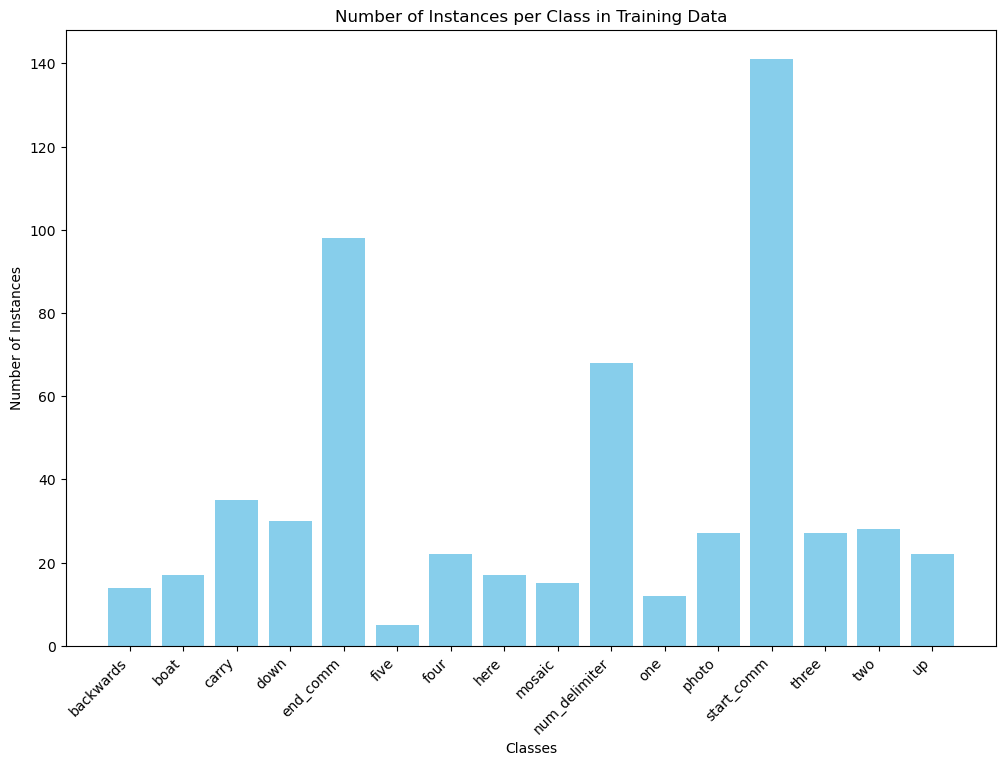

In [62]:
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

# Count the instances per class in the training data
class_counts = Counter(y_train)

# Retrieve class names from the label encoder
class_names = label_encoder.classes_

# Ensure the class names are in the same order as the class indices
# Create a list with counts for each class, in the order of class names
instance_counts = [class_counts.get(i, 0) for i in range(len(class_names))]

# Plot results
plt.figure(figsize=(12, 8))
plt.bar(class_names, instance_counts, color='skyblue')
plt.xlabel('Classes')
plt.ylabel('Number of Instances')
plt.title('Number of Instances per Class in Training Data')
plt.xticks(rotation=45, ha='right')
plt.show()

Clearly our model is better at recognizing some gestures than others, with some in the 70-90% accuracy range. I suspect that visually distinct gestures such as “carry” maintained the highest accuracies because they are easiest to detect, while gestures with similar counterparts such as “one,” “two,” and “up” scored low accuracies as they are easy to confuse.

It's also important to notice that a few underrepresented gestures in the dataset scored low accuracies. The gesture “five” has so few instances that it did not even appear in the validation set, and so was not even tested. Overall, however, while extreme underrepresentation correlates with low accuracy for a class, many moderately underrepresented classes still did well. The classes "down" and "four," for example, achieved average accuracies around 50% while having relatively few training examples in the dataset. This leads me to believe that there was simply not enough data on "five" to be analyzed and generalized.

Overall, this version of the model represents that deep learning does in fact have the potential for gesture recognition in specialized environments in the human-robot interaction field. Based on my research so far, the approach of combining 2D CNNs with LSTMs shows promise in capturing both spatial and temporal features of gestures.

# Future Work

Given more time, my next attempt would take an existing CNN pre-trained to extract human body and hand positions. This could serve as the backbone for the model, allowing it to extract posture features to send to an RNN for gesture recognition. Since the limited amount and diversity of training data would not be as much of a problem, I believe this proposed model could achieve much higher accuracy with the same input data.

# Conclusions

This project explored the use of deep learning for gesture recognition in underwater environments, utilizing the CADDY Underwater Gesture Dataset. After a comprehensive process of trial and error, the model successfully achieved a gesture recognition accuracy of 50%.

## Limitations
- With the current model, there are only 16 specific valid gestures. This makes it less flexible if roboticists want to make changes to the gesture set.
- The divers recorded in the dataset wear specific gloves that would likely be needed to use this model in practice.
- The current model identifies gestures in individual video clips, but is not currently designed to categorize multiple sequential gestures in a continuous video feed.

## Benefits
- With some gestures reaching as high as 90% accuracy, this could still potentially work well enough for certain scenarios depending on the requirements, for instance if there are alternative forms of verification alongside hand gestures.
- On average, the model recognizes gestures with 50% accuracy. While not ideal, this model demonstrates that deep learning with a neural network is a viable solution for gesture recognition.
- There is still room for improvement, and the research done so far provides a solid foundation for future work.

Overall, this project has laid a solid foundation for developing intuitive gesture-based communication systems for robots. While the current accuracy of 50% represents a starting point, it underscores the potential for further advancements and refinements in this area. The findings provide valuable insights into the challenges and possibilities of gesture recognition in specialized environments, helping to pave the way for future research and development.